## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jiei Ota

**Date:** 10/14/2026

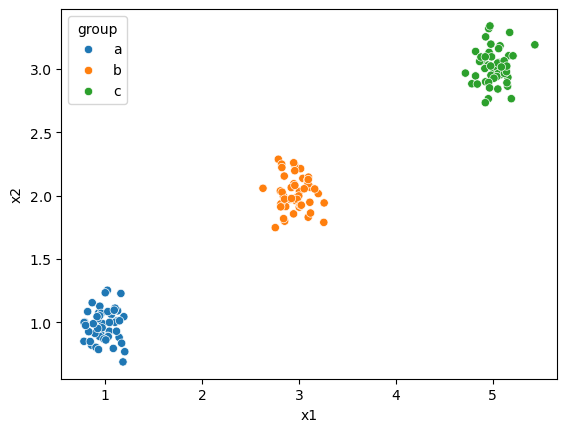

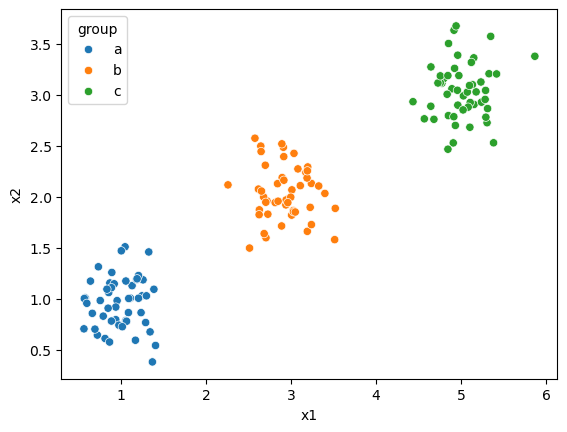

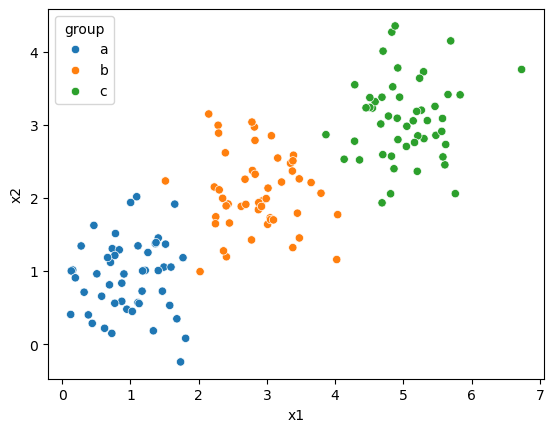

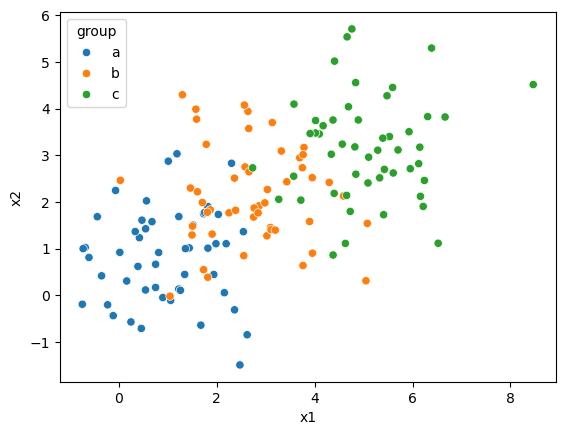

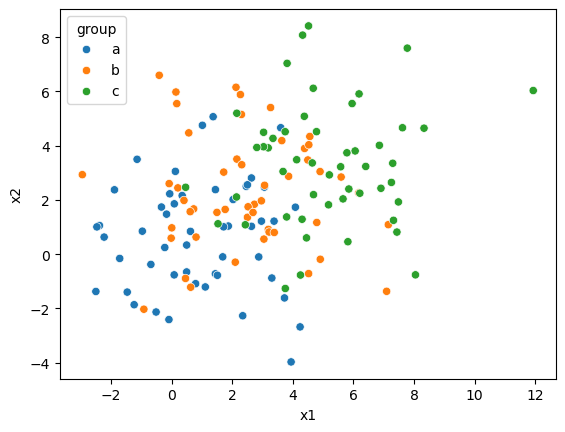

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

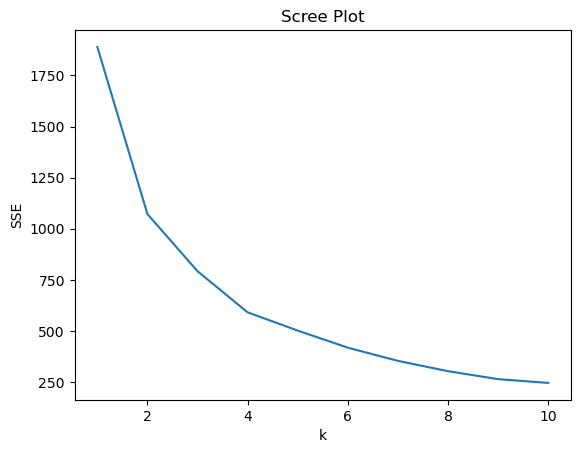

In [ ]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#Q2: The visual distinctness of th e clusters decreases as the noise increased. 
for df in [df0_125, df0_25, df0_5, df1_0, df2_0]:
    sns.scatterplot(data=df,x='x1',y='x2',hue='group')
    plt.show()

#Q3: As the noise increases, the optimal cluster count appears to be less distinct. For lower noises, the elbow method shows a more clear "elbow" in the chart. 
from sklearn.cluster import KMeans


X = df[["x1", "x2"]]

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

#Q4: The intuition of the elbow method is that as the number of cluster increases the data points get closer to the center. However,
# at a certain point near the "elbow", the decrease in distance is no longer significant enough to justify an increase in cluster count. 




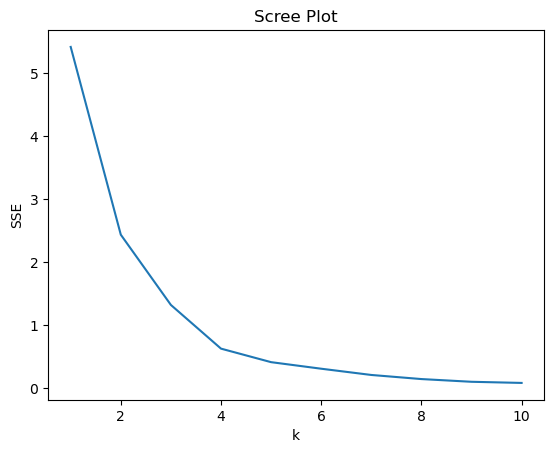

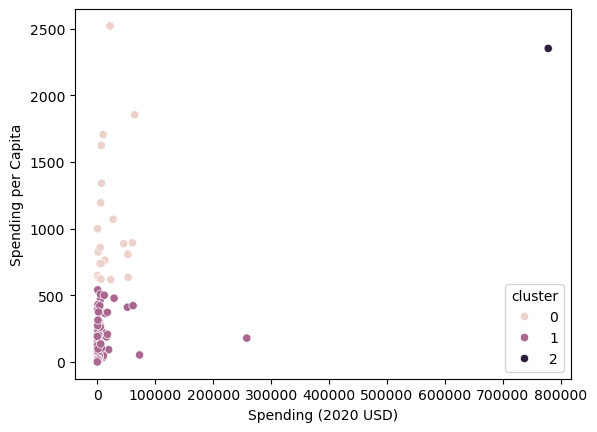

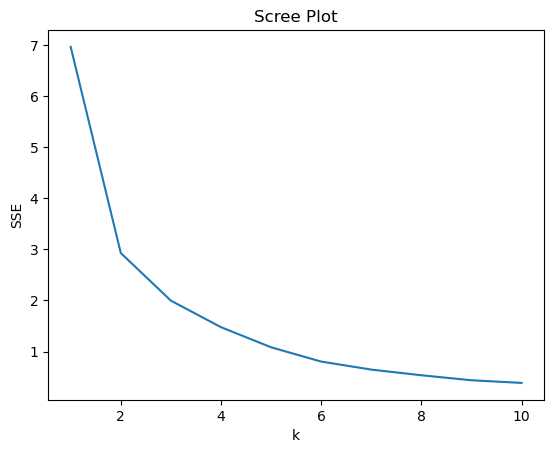

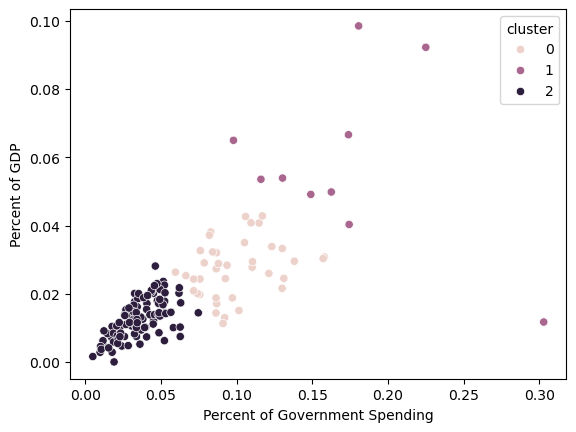

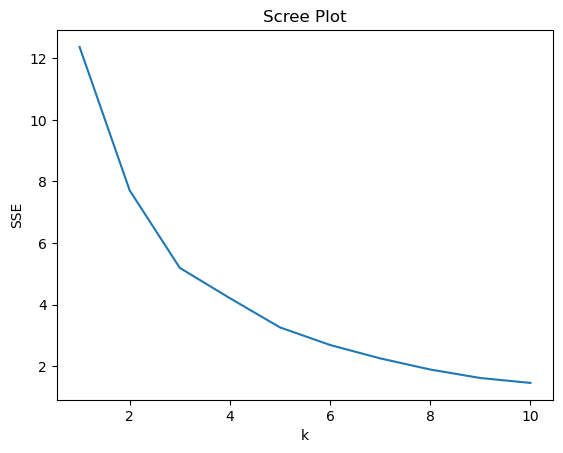

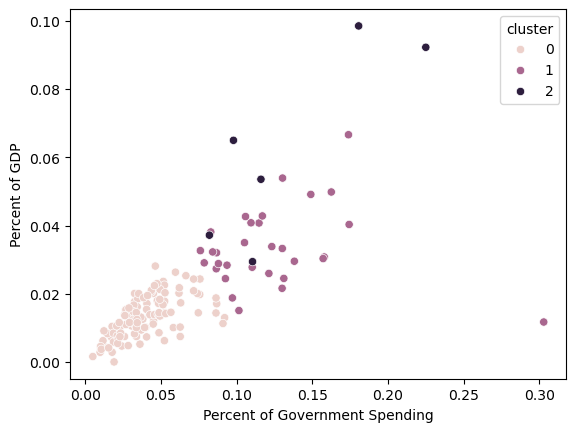

5.0

In [ ]:
#Second question
#Q2.1: No other cleaning is needed for the data set until we know what our objective is or the correct constraints for each column. I've commented out spending per capita to be >= 0, but typically that should be a positive value. 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('/Users/jieiota/Documents/Year 3 Semester 1/DS 3001/A04-clustering/data/SIPRI Military Expenditure Database.csv')
df.head()
df = df.dropna()
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df = df[df['Year'] == 2020]
#df = df[df['Spending per Capita'] >= 0]
#print(df['Spending per Capita'].min())
df.shape


#Q2.2: There is not much correlation in the scatterplot and the US along with most of the other countries have spent very few in the spending (2020 USD) causing the data to hover closer to the left side. 

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
#Max-min normalize
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
#Scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot", xlabel="k", ylabel="SSE"
)
plt.show()
#Scatterplot
model = KMeans(
    n_clusters=3, n_init=10, random_state=0
).fit(X)
df["cluster"] = model.labels_
df.groupby("cluster").describe()

sns.scatterplot(
    data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster"
)
plt.show()


#Q2.3: These results show more of a correlation between the two variables: Percent of Government Spending and Percent of GDP. Additionally,
# the elbow is more distinct in the first instance with spending. 

features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
#Max-min normalize
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
#Scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot", xlabel="k", ylabel="SSE"
)
plt.show()
#Scatterplot
model = KMeans(
    n_clusters=3, n_init=10, random_state=0
).fit(X)
df["cluster"] = model.labels_
df.groupby("cluster").describe()

sns.scatterplot(
    data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster"
)
plt.show()

#Q2.4: The SSE is higher in this question which means that the clusters are more spread out. 
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
#Max-min normalize
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
#Scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot", xlabel="k", ylabel="SSE"
)
plt.show()
#Scatterplot
model = KMeans(
    n_clusters=3, n_init=10, random_state=0
).fit(X)
df["cluster"] = model.labels_
df.groupby("cluster").describe()

sns.scatterplot(
    data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster"
)
plt.show()

#Q5:
5. #Yes, the screen plot was able to identify a reasonable number of clusters for the set with around 4 clusters for the optimal SSE before the increased cluster impact becomes marginal.
#Additionally, through the scatter plot, we are able to see that cluster two hovers closer to the origin and cluster appears to be spread out the furthest. 









## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ca7873ac657dce3146ed7d9b1191142055442a49
- **AI tool and model used:** Chat GPT 6

### *Prompts used

1. Did I answer all the questions properly?
2. How would I general all five charts most optimally?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Expanding on question 1.2 to explain that increasing noise causes clusters to spread out and overlap more.
2. Add a for loop to generate scree plots for all five datasets, not just df2_0.
3. Specify that SSE measures squared distances and explain why k = 3 makes sense for the original three groups.

4. Confirm you have 148 countries. Check whether numeric columns contain negative values or other invalid entries. Convert Year to numeric before filtering and dropping missing values.
5. Your explanation about the US is incorrect. The United States is one of the highest military spenders, not among the lowest. Identify its cluster using df[df["Country"] == "United States"] (adjust the column name if needed). Explain what distinguishes the three clusters using your .groupby("cluster").describe() results. For example, compare average spending between clusters.
6. Your explanation is reasonable, but describe how countries are grouped differently when using spending percentages instead of absolute spending.
7. Your scatterplot only displays two variables, even though clustering uses four. That's acceptable, but clarify that the colors represent clusters determined using all four variables.
8. Explain what useful patterns K-means identified about military spending, rather than focusing only on the elbow method.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Added more clarification |
| 2 | Accept | Created to answer full question |
| 3 | Accept | Included proper terminology |
| 4-8 | Accept | Helped improve the overall explanation rather than just a generic result |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

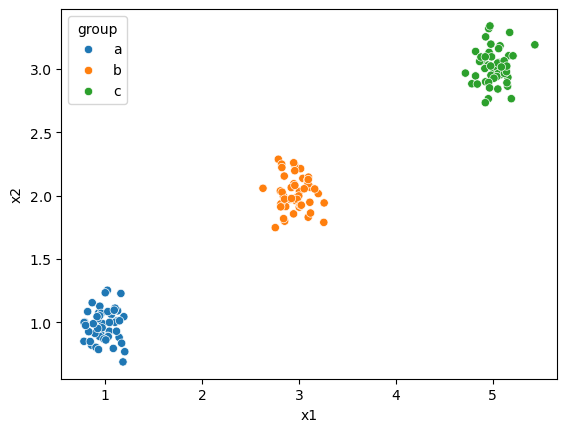

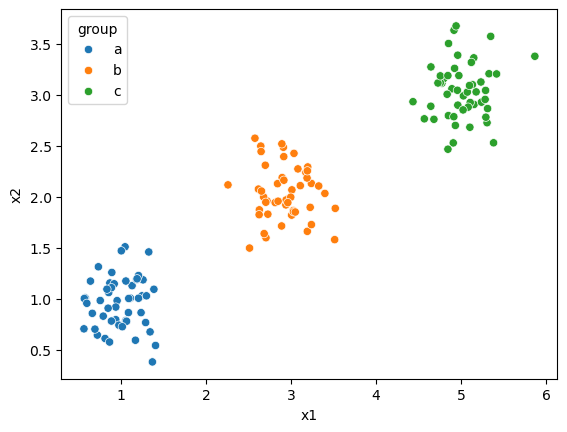

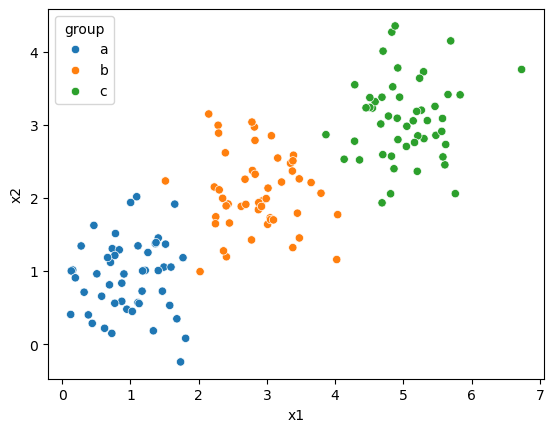

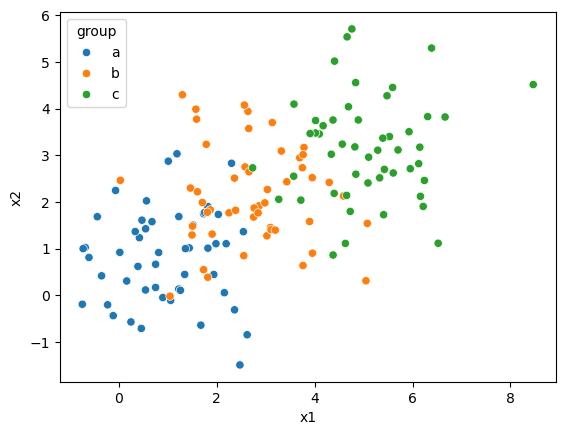

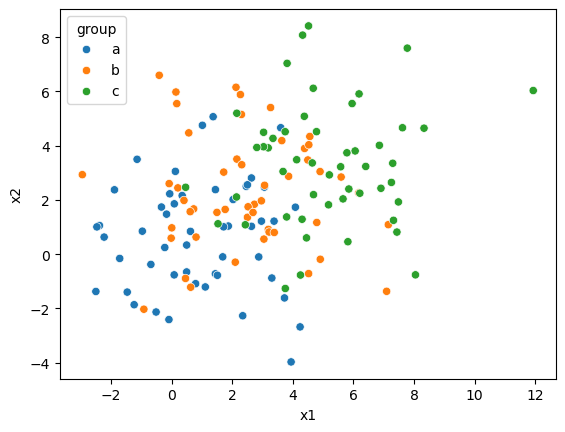

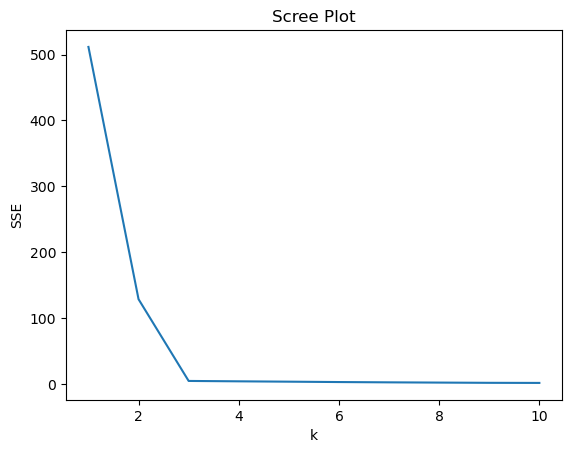

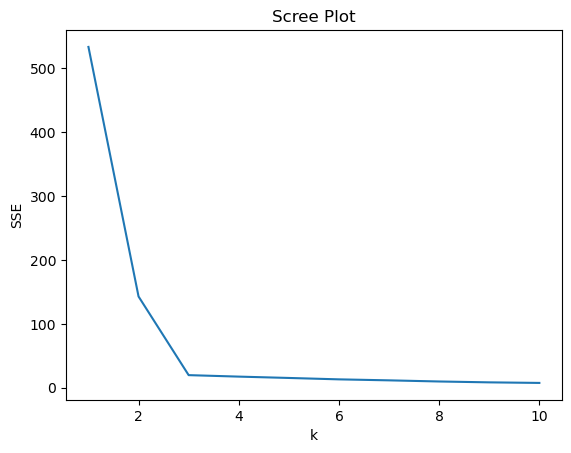

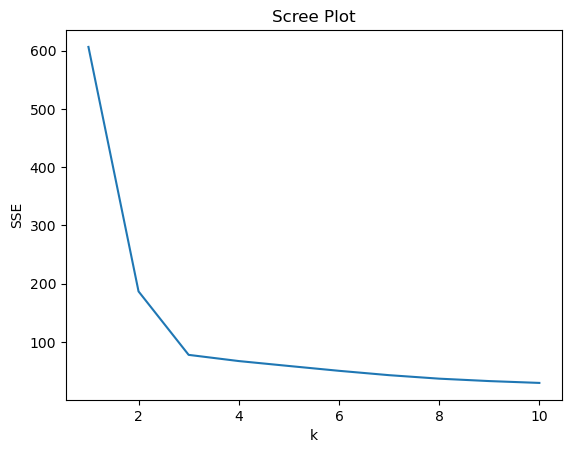

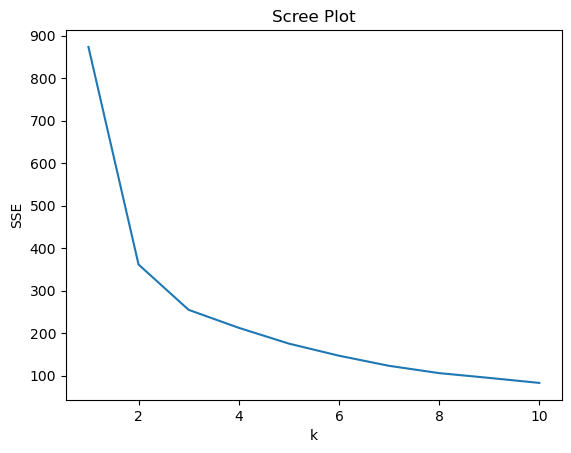

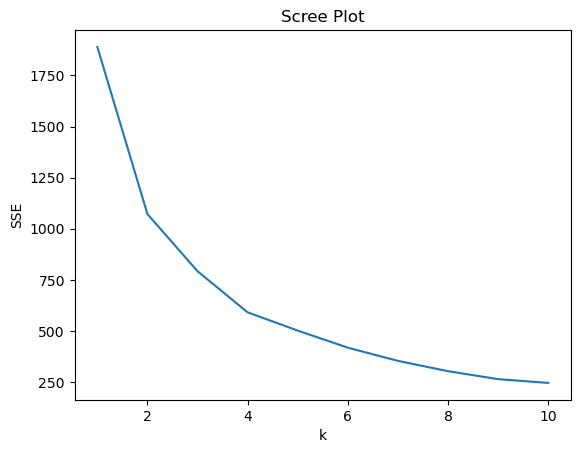

In [ ]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#Q2: The visual distinctness of the clusters decreases as the noise increased. As noise increases, the points become more spread out and clusters overlap. 
for df in [df0_125, df0_25, df0_5, df1_0, df2_0]:
    sns.scatterplot(data=df,x='x1',y='x2',hue='group')
    plt.show()

#Q3: As the noise increases, the optimal cluster count appears to be less distinct. For lower noises, the elbow method shows a more clear "elbow" in the chart. 
from sklearn.cluster import KMeans

ks = np.arange(1, 11)

for df in [df0_125, df0_25, df0_5, df1_0, df2_0]:
    X = df[["x1", "x2"]]

    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    plt.figure()
    sns.lineplot(x=ks, y=SSE).set(
        title="Scree Plot", xlabel="k", ylabel="SSE"
    )
    plt.show()

#Q4: As the cluster count increases, the sum of squared errors (SSE) decreases.
# The intuition of the elbow method is that as the number of cluster increases the data points get closer to the center. However,
# at a certain point near the "elbow", the decrease in distance becomes marginal and is no longer significant enough to justify an increase in cluster count. 



(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
Spending (2020 USD)               8.622460
Spending per Capita               0.580129
Percent of Government Spending    0.004896
Percent of GDP                    0.000054
dtype: float64


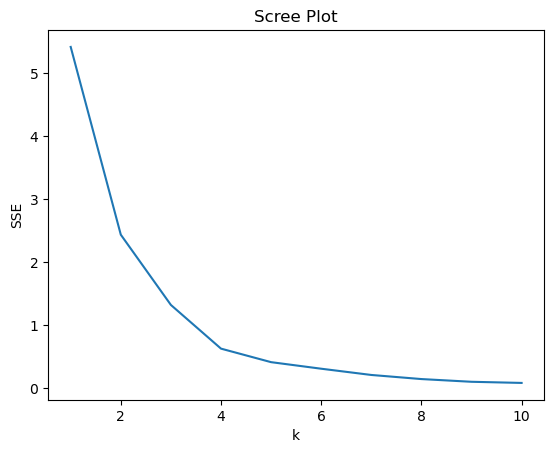

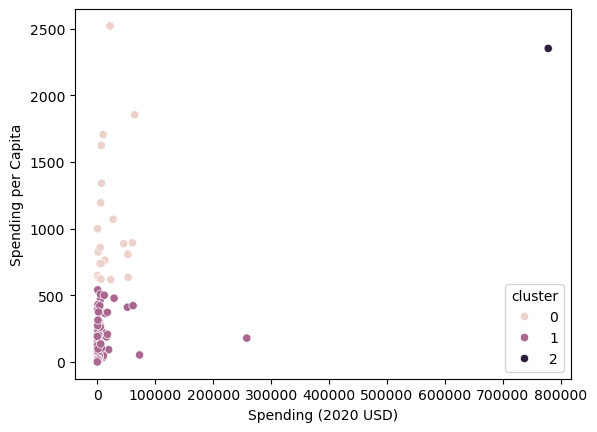

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

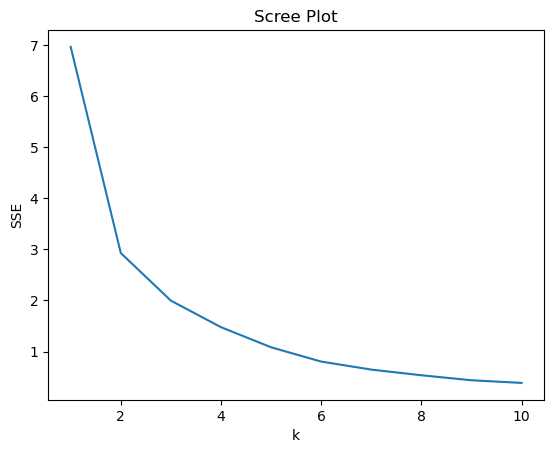

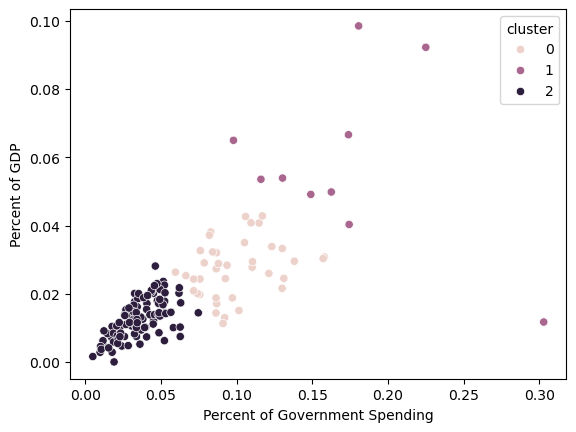

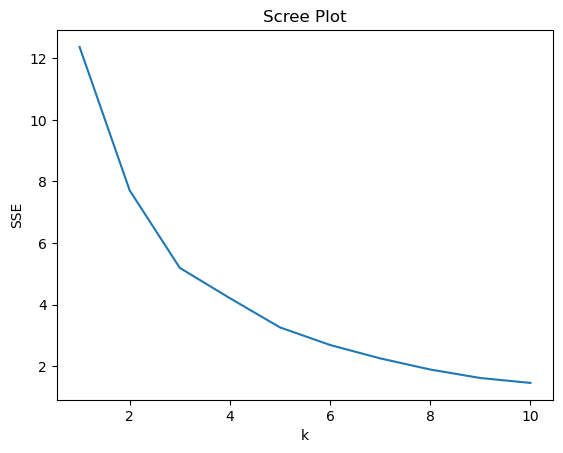

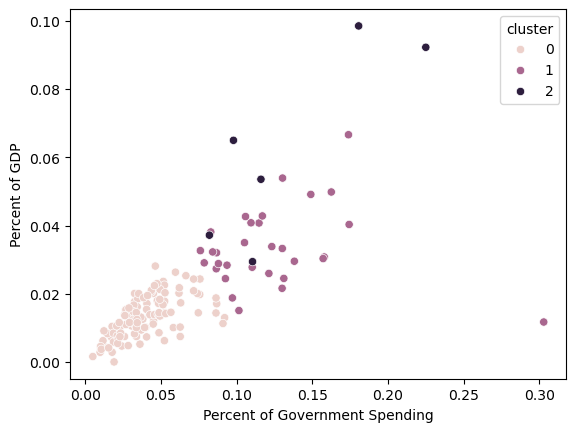

5.0

In [ ]:
#Q2.1: Checked the numerical values to ensure there were no logically invalid values. 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('/Users/jieiota/Documents/Year 3 Semester 1/DS 3001/A04-clustering/data/SIPRI Military Expenditure Database.csv')

df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df = df[df['Year'] == 2020].dropna()
print(df.shape)
print(df.dtypes)
print(df[["Spending (2020 USD)", "Spending per Capita",
          "Percent of Government Spending", "Percent of GDP"]].min())


#Q2.2: There is not much correlation in the scatterplot but the US unlike most of the other countries has spent a large amount of on its military spending. 
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
#Max-min normalize
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
#Scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot", xlabel="k", ylabel="SSE"
)
plt.show()
#Scatterplot
model = KMeans(
    n_clusters=3, n_init=10, random_state=0
).fit(X)
df["cluster"] = model.labels_
df.groupby("cluster").describe()

sns.scatterplot(
    data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster"
)
plt.show()
print(df.groupby("cluster")[features].describe())
print(df[df["Country"] == "United States"])
print(df[df["cluster"] == 2][["Country", "Spending (2020 USD)", "cluster"]])

#Q2.3: The scatterplot shows a strong positive correlation between Percent of Government Spending and Percent of GDP 
# compared to the variables in Q2. Unlike Q2, which groups countries based on how much they spend, Q3 groups 
# countries based on the proportion of resources.

features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
#Max-min normalize
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
#Scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot", xlabel="k", ylabel="SSE"
)
plt.show()
#Scatterplot
model = KMeans(
    n_clusters=3, n_init=10, random_state=0
).fit(X)
df["cluster"] = model.labels_
df.groupby("cluster").describe()

sns.scatterplot(
    data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster"
)
plt.show()

#Q2.4: The SSE is higher in this question which means that the clusters are more spread out. The SSE is higher 
# when using all four variables compared to using only two. This is because the algorithm is calculating squared distances 
# across more dimensions. Using all four variables allows K-means to group countries based on both their overall military spending 
# and the percentage of resources allocated toward the military.
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
#Max-min normalize
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
#Scree plot
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot", xlabel="k", ylabel="SSE"
)
plt.show()
#Scatterplot
model = KMeans(
    n_clusters=3, n_init=10, random_state=0
).fit(X)
df["cluster"] = model.labels_
df.groupby("cluster").describe()

sns.scatterplot(
    data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster"
)
plt.show()

#Q5:
5. #Yes, the screen plot was able to identify a reasonable number of clusters for the set with around 4 clusters for the optimal SSE before the increased cluster impact becomes marginal.
#Additionally, through the scatter plot, we are able to see that cluster two hovers closer to the origin and cluster appears to be spread out the furthest. 


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements with AI was its capability to double check my graphs alonside my code and optimize it wherever it saw fit. Additionally, the use of generative AI helped tremendously with the explanation portion of this assignment especially because there were some parts where I was unsure of how to word my findings exactly. Much of the final solution was verified by checking at the visuals developed through the code. Overall, as time progresses the limitations of AI seem to be diminishing more and more with the only downside that I could think of is that it could also provide unsolicited advice. When I prompted it a question, sometimes it would trail off into answering another follow up question as well that wasn't initially asked for. Additionally though, sometimes given the code I had initially wrote, AI is able to find and suggest ways to remove unecessary code which is useful at times to help clean up the coding space. 